# CALCE CX2 — Five-model SOH benchmark

Train **PINN (MLP + soft physics)**, **LSTM**, **LSTM–PINN**, **causal CNN–PINN**, and **causal Transformer** on the same battery-disjoint split, with the same five charging-derived features.

- Uses `train_final_filtered.csv` when available; otherwise raises an error (unless you deliberately change the filename).
- Uses unchanged `validation.csv` and `test.csv`.
- **Never bridges removed/missing cycle ordinals** when forming windows. Model predictions are per-cycle, with the final window timestep scored.
- Includes fitted-on-train-only standardization, early stopping, multiple seeds, saved weights, predictions, loss curves and metrics.
- A **soft monotonicity constraint** is *not* a full electrochemical governing equation; measured accessible capacity can legitimately fluctuate. Results should be labeled *physics-guided*, not mechanistically validated PINN.
- Zero-feature temporal windows are not invented; only valid consecutive-cycle segments yield samples. A threshold-filtered dataset changes the evaluated training distribution.

Run all cells in order. For a fast functionality check set `EPOCHS=1`, `SEEDS=(42,)`, and `MAX_TRAIN_BATCHES=2`, then restore research settings.

In [ ]:
# Run once if dependencies are missing:
# %pip install torch pandas numpy matplotlib scikit-learn tqdm

In [1]:
from pathlib import Path
import os, json, random, time, copy, zipfile, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

DATA_DIR = Path(r"C:\Projects\Battery_Soh\pre processed ready to use data")
TRAIN_NAME = "train_final_filtered.csv"
OUTPUT_DIR = Path("soh_five_model_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = ["cc_duration_s", "cv_duration_s", "dva_peak", "ic_peak_voltage", "ic_peak_width"]
TARGET = "soh"
SEQ_LEN = 12
BATCH_SIZE = 128
EPOCHS = 80
PATIENCE = 15
LR = 1e-3
WEIGHT_DECAY = 1e-4
PHYSICS_WEIGHT = 0.5       # scale is on squared SOH units; tune ONLY using validation
SEEDS = (42, 123, 2026)   # run 1 seed first if desired
HIDDEN = 64
MAX_TRAIN_BATCHES = None   # integer e.g. 2 ONLY for smoke testing
NUM_WORKERS = 0            # Windows/Jupyter-safe
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
print("PyTorch", torch.__version__)

Device: cuda GPU: NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch 2.11.0+cu128


In [2]:
# Optionally unzip original provided data for schema smoke testing;
# DO NOT confuse the original CSV with your locally filtered CSV.
required = [DATA_DIR / TRAIN_NAME, DATA_DIR / "validation.csv", DATA_DIR / "test.csv"]
missing = [str(x) for x in required if not x.exists()]
if missing:
    raise FileNotFoundError(f"Missing required dataset files: {missing}. Check DATA_DIR and TRAIN_NAME. Do not substitute original train.csv silently.")

def load_split(path):
    df = pd.read_csv(path)
    expected = set(FEATURES + [TARGET,"battery","cycle_ordinal"])
    assert expected.issubset(df.columns), f"{path.name}: missing {expected - set(df.columns)}"
    assert df[FEATURES + [TARGET,"cycle_ordinal"]].notna().all().all(), f"NaNs in {path.name}"
    assert not df.duplicated(["battery","cycle_ordinal"]).any(), f"Duplicate battery/ordinal in {path.name}"
    return df.sort_values(["battery","cycle_ordinal"]).reset_index(drop=True)

splits = {"train":load_split(DATA_DIR / TRAIN_NAME),
          "validation":load_split(DATA_DIR / "validation.csv"),
          "test":load_split(DATA_DIR / "test.csv")}
for name, df in splits.items():
    print(name, len(df), sorted(df.battery.unique()))
for a,b in [("train","validation"),("train","test"),("validation","test")]:
    assert set(splits[a].battery).isdisjoint(set(splits[b].battery)), "Battery leakage!"

mean = splits["train"][FEATURES].mean().to_numpy(dtype=np.float32)
std = splits["train"][FEATURES].std(ddof=0).to_numpy(dtype=np.float32)
std = np.where(std < 1e-8, 1., std)
(OUTPUT_DIR / "scaler.json").write_text(json.dumps({"features":FEATURES,"mean":mean.tolist(),"std":std.tolist()},indent=2))
print("Train-only normalization saved.")

train 7690 ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
validation 1743 ['CX2_36']
test 1477 ['CX2_38']
Train-only normalization saved.


In [3]:
class CycleWindows(Dataset):
    """Only windows with strictly consecutive cycle ordinals from a single battery."""
    def __init__(self, frame, mean, std, seq_len):
        self.x, self.y, self.metadata = [], [], []
        self.seq_len = seq_len
        for battery, cell in frame.groupby("battery",sort=False):
            cell = cell.sort_values("cycle_ordinal").reset_index(drop=True)
            ords = cell.cycle_ordinal.to_numpy()
            breaks = np.r_[0, np.where(np.diff(ords) != 1)[0] + 1, len(cell)]
            for left,right in zip(breaks[:-1],breaks[1:]):
                part = cell.iloc[left:right]
                if len(part) < seq_len: continue
                vals = ((part[FEATURES].to_numpy(dtype=np.float32) - mean)/std)
                ys = part[TARGET].to_numpy(dtype=np.float32)
                for j in range(seq_len-1,len(part)):
                    self.x.append(vals[j-seq_len+1:j+1].copy())
                    self.y.append(ys[j-seq_len+1:j+1].copy())
                    row=part.iloc[j]
                    self.metadata.append({"battery":str(battery), "cycle_ordinal":int(row.cycle_ordinal), "soh":float(ys[j])})
        if not self.x:
            raise ValueError(f"No valid windows for seq_len={seq_len}; inspect filtering and cycle gaps.")
        self.x = np.asarray(self.x,dtype=np.float32)
        self.y = np.asarray(self.y,dtype=np.float32)
    def __len__(self): return len(self.x)
    def __getitem__(self,index): return torch.from_numpy(self.x[index]), torch.from_numpy(self.y[index])

datasets = {name:CycleWindows(frame,mean,std,SEQ_LEN) for name,frame in splits.items()}
for name,ds in datasets.items():
    print(name, "windows:", len(ds), "excluded by missing-history/windows:",len(splits[name])-len(ds))

def get_loaders(seed):
    gen=torch.Generator().manual_seed(seed)
    return {
      "train":DataLoader(datasets["train"],batch_size=BATCH_SIZE,shuffle=True, generator=gen,num_workers=NUM_WORKERS),
      "validation":DataLoader(datasets["validation"],batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS),
      "test":DataLoader(datasets["test"],batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)
    }

train windows: 3869 excluded by missing-history/windows: 3821
validation windows: 918 excluded by missing-history/windows: 825
test windows: 752 excluded by missing-history/windows: 725


## Model families

All models return one prediction for every timestep of a history window. We supervise the **final** prediction only and use earlier predictions solely for the optional soft monotonic penalty. The CNN uses left-only padding and the Transformer uses a causal attention mask; neither sees future features within a window. Same `SEQ_LEN` and final-step label across models.

The MLP–PINN operates on **the current timestep** only; it serves as a non-memory physics-guided reference. The standard LSTM and Transformer have no physics penalty. The CNN–PINN uses a temporal causal 1D CNN feature extractor followed by an MLP SOH head.

In [4]:
class PerStepMLP(nn.Module):
    def __init__(self, d=5, h=64):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(d,h),nn.ReLU(),nn.Linear(h,h),nn.ReLU(),nn.Linear(h,1))
    def forward(self,x):return self.net(x).squeeze(-1)

class LSTMModel(nn.Module):
    def __init__(self,d=5,h=64):
        super().__init__()
        self.lstm=nn.LSTM(d,h,num_layers=1,batch_first=True)
        self.head=nn.Sequential(nn.Linear(h,h//2),nn.ReLU(),nn.Linear(h//2,1))
    def forward(self,x):return self.head(self.lstm(x)[0]).squeeze(-1)

class CausalConv1d(nn.Module):
    def __init__(self, cin,cout,k=3,dilation=1):
        super().__init__(); self.pad=(k-1)*dilation
        self.conv=nn.Conv1d(cin,cout,kernel_size=k,dilation=dilation)
    def forward(self,x):return self.conv(nn.functional.pad(x,(self.pad,0)))

class CNNModel(nn.Module):
    def __init__(self,d=5,h=64):
        super().__init__()
        self.conv=nn.Sequential(CausalConv1d(d,h,3,1),nn.ReLU(),
                                CausalConv1d(h,h,3,2),nn.ReLU())
        self.head=nn.Sequential(nn.Linear(h,h//2),nn.ReLU(),nn.Linear(h//2,1))
    def forward(self,x):return self.head(self.conv(x.transpose(1,2)).transpose(1,2)).squeeze(-1)

class TransformerModel(nn.Module):
    def __init__(self,d=5,h=64,nhead=4,layers=2,max_len=2048):
        super().__init__()
        self.input=nn.Linear(d,h)
        self.pos=nn.Embedding(max_len,h)
        enc=nn.TransformerEncoderLayer(d_model=h,nhead=nhead,dim_feedforward=h*2,
                                        dropout=0.1,batch_first=True,activation="gelu")
        self.encoder=nn.TransformerEncoder(enc,num_layers=layers,enable_nested_tensor=False)
        self.head=nn.Linear(h,1)
    def forward(self,x):
        b,t,_=x.shape
        idx=torch.arange(t,device=x.device)
        z=self.input(x)+self.pos(idx)[None,:,:]
        causal_mask=torch.triu(torch.ones(t,t,device=x.device,dtype=torch.bool), diagonal=1)
        z=self.encoder(z,mask=causal_mask)
        return self.head(z).squeeze(-1)

MODEL_SPECS={
    "pinn_mlp":(lambda:PerStepMLP(len(FEATURES),HIDDEN),True),
    "lstm":(lambda:LSTMModel(len(FEATURES),HIDDEN),False),
    "lstm_pinn":(lambda:LSTMModel(len(FEATURES),HIDDEN),True),
    "cnn_pinn":(lambda:CNNModel(len(FEATURES),HIDDEN),True),
    "transformer":(lambda:TransformerModel(len(FEATURES),HIDDEN),False),
}

def objective(pred,y,with_physics):
    pred_last=pred[:,-1]
    target_last=y[:,-1]
    data_loss=((pred_last-target_last)**2).mean()
    # Compare predictions at consecutive timesteps WITHIN verified consecutive-cycle windows.
    # This is a weak irreversible-aging prior, not a measured-capacity governing PDE.
    physics=torch.relu(pred[:,1:]-pred[:,:-1]).square().mean() if with_physics else data_loss.new_zeros(())
    return data_loss+PHYSICS_WEIGHT*physics, data_loss, physics

def set_seed(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

In [5]:
def evaluate(model,loader,with_physics):
    model.eval(); losses=[]; preds=[]; ys=[]
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(DEVICE),y.to(DEVICE)
            out=model(x)
            loss,_,_=objective(out,y,with_physics)
            losses.append((float(loss),len(x)))
            preds.extend(out[:,-1].cpu().numpy().tolist())
            ys.extend(y[:,-1].cpu().numpy().tolist())
    return sum(v*n for v,n in losses)/sum(n for _,n in losses), np.array(ys),np.array(preds)

def metrics(y,p):
    err=p-y
    return {"RMSE":float(np.sqrt(np.mean(err**2))),
            "MAE":float(np.mean(np.abs(err))),
            "MAPE_pct":float(100*np.mean(np.abs(err)/np.maximum(np.abs(y),1e-8))),
            "R2":float(1-np.sum(err**2)/np.sum((y-y.mean())**2)) if np.sum((y-y.mean())**2)>0 else float('nan')}

def save_predictions(split, model_name, seed, y, p):
    records=pd.DataFrame(datasets[split].metadata)
    records["predicted_soh"]=p
    records["error_soh"]=p-y
    records.to_csv(OUTPUT_DIR/f"{model_name}_seed{seed}_{split}_predictions.csv",index=False)

def train_one(model_name, seed):
    set_seed(seed)
    model, with_physics = MODEL_SPECS[model_name][0]().to(DEVICE),MODEL_SPECS[model_name][1]
    loaders=get_loaders(seed)
    opt=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    best=float('inf');best_state=None; patience=0;history=[]
    start=time.perf_counter()
    for epoch in range(1,EPOCHS+1):
        model.train(); running=[]
        for batch_idx,(x,y) in enumerate(loaders["train"]):
            if MAX_TRAIN_BATCHES is not None and batch_idx >= MAX_TRAIN_BATCHES:break
            x,y=x.to(DEVICE),y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            pred=model(x)
            loss,data_loss,physics=objective(pred,y,with_physics)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.0)
            opt.step()
            running.append((float(loss.detach()),len(x)))
        train_loss=sum(v*n for v,n in running)/sum(n for _,n in running)
        val_loss,_,_=evaluate(model,loaders["validation"],with_physics)
        history.append({"epoch":epoch,"train_loss":train_loss,"validation_loss":val_loss})
        if val_loss < best - 1e-8:
            best=val_loss; best_state=copy.deepcopy(model.state_dict());patience=0
        else:
            patience+=1
            if patience>=PATIENCE:break
        if epoch==1 or epoch%10==0:
            print(f"{model_name} seed={seed} epoch={epoch:3d}: train={train_loss:.6f}, val={val_loss:.6f}")
    model.load_state_dict(best_state)
    elapsed=time.perf_counter()-start
    torch.save({"state_dict":model.state_dict(),"model_name":model_name,"seed":seed,
                "features":FEATURES,"seq_len":SEQ_LEN,"physics_weight":PHYSICS_WEIGHT},
               OUTPUT_DIR/f"{model_name}_seed{seed}.pt")
    pd.DataFrame(history).to_csv(OUTPUT_DIR/f"{model_name}_seed{seed}_history.csv",index=False)
    rows=[]
    for split,loader in loaders.items():
        _,y,p=evaluate(model,loader,with_physics)
        save_predictions(split,model_name,seed,y,p)
        rows.append({"model":model_name,"seed":seed,"split":split,"n_windows":len(y),
                     "epochs_trained":len(history),"train_seconds":round(elapsed,3),
                     "parameters":sum(q.numel() for q in model.parameters()),**metrics(y,p)})
    return rows

In [6]:
# Full training: 5 models × 3 seeds. On CPU this may take substantial time.
# For an initial check, set SEEDS=(42,), EPOCHS=1, MAX_TRAIN_BATCHES=2 above.
config={"data_dir":str(DATA_DIR),"train_name":TRAIN_NAME,"features":FEATURES,"seq_len":SEQ_LEN,
        "batch_size":BATCH_SIZE,"epochs":EPOCHS,"patience":PATIENCE,"lr":LR,
        "weight_decay":WEIGHT_DECAY,"physics_weight":PHYSICS_WEIGHT,"seeds":SEEDS,
        "max_train_batches":MAX_TRAIN_BATCHES,"device":str(DEVICE),
        "data_counts":{k:len(v) for k,v in splits.items()},
        "window_counts":{k:len(v) for k,v in datasets.items()}}
(OUTPUT_DIR/"config.json").write_text(json.dumps(config,indent=2,default=list))
all_rows=[]
for model_name in MODEL_SPECS:
    for seed in SEEDS:
        all_rows.extend(train_one(model_name,seed))
        pd.DataFrame(all_rows).to_csv(OUTPUT_DIR/"metrics_all_runs.csv",index=False)
results=pd.DataFrame(all_rows)
display(results[results.split=="test"].sort_values("RMSE"))

pinn_mlp seed=42 epoch=  1: train=0.246360, val=0.038061
pinn_mlp seed=42 epoch= 10: train=0.000166, val=0.002695
pinn_mlp seed=42 epoch= 20: train=0.000074, val=0.001903
pinn_mlp seed=42 epoch= 30: train=0.000048, val=0.000965
pinn_mlp seed=42 epoch= 40: train=0.000039, val=0.000692
pinn_mlp seed=42 epoch= 50: train=0.000034, val=0.000448
pinn_mlp seed=42 epoch= 60: train=0.000034, val=0.000342
pinn_mlp seed=42 epoch= 70: train=0.000028, val=0.000202
pinn_mlp seed=42 epoch= 80: train=0.000028, val=0.000265
pinn_mlp seed=123 epoch=  1: train=0.208713, val=0.046250
pinn_mlp seed=123 epoch= 10: train=0.000127, val=0.002146
pinn_mlp seed=123 epoch= 20: train=0.000075, val=0.001274
pinn_mlp seed=123 epoch= 30: train=0.000056, val=0.000995
pinn_mlp seed=123 epoch= 40: train=0.000043, val=0.000640
pinn_mlp seed=123 epoch= 50: train=0.000036, val=0.000592
pinn_mlp seed=123 epoch= 60: train=0.000034, val=0.000422
pinn_mlp seed=123 epoch= 70: train=0.000031, val=0.000301
pinn_mlp seed=123 epoch

,model,seed,split,n_windows,epochs_trained,train_seconds,parameters,RMSE,MAE,MAPE_pct,R2
41,transformer,123,test,752,41,15.756,198465,0.009872,0.008870,1.127773,0.993740
44,transformer,2026,test,752,35,13.917,198465,0.013408,0.012420,1.552181,0.988453
38,transformer,42,test,752,22,8.263,198465,0.014983,0.013085,1.602449,0.985579
26,lstm_pinn,2026,test,752,80,12.862,20289,0.015785,0.014947,1.985509,0.983995
23,lstm_pinn,123,test,752,80,13.112,20289,0.015823,0.014909,1.996823,0.983917
35,cnn_pinn,2026,test,752,79,11.882,15489,0.016522,0.014906,1.968400,0.982465
17,lstm,2026,test,752,66,9.700,20289,0.016697,0.015763,2.095701,0.982091
32,cnn_pinn,123,test,752,80,11.762,15489,0.016728,0.014583,1.860892,0.982026
20,lstm_pinn,42,test,752,80,13.050,20289,0.017542,0.015432,2.152330,0.980233
14,lstm,123,test,752,80,11.899,20289,0.018018,0.016246,2.193666,0.979145


In [7]:
# Aggregate results by model / evaluation split. No fabricated benchmark values.
summary=(results.groupby(["split","model"])
         .agg(RMSE_mean=("RMSE","mean"),RMSE_std=("RMSE","std"),
              MAE_mean=("MAE","mean"),MAE_std=("MAE","std"),
              MAPE_mean=("MAPE_pct","mean"),R2_mean=("R2","mean"),
              n_seeds=("seed","nunique"))
         .reset_index())
summary.to_csv(OUTPUT_DIR/"metrics_summary.csv",index=False)
display(summary[summary.split=="test"].sort_values("RMSE_mean"))

,split,model,RMSE_mean,RMSE_std,MAE_mean,MAE_std,MAPE_mean,R2_mean,n_seeds
4,test,transformer,0.012754,0.002618,0.011458,0.002266,1.427468,0.989257,3
2,test,lstm_pinn,0.016383,0.001004,0.015096,0.000292,2.044887,0.982715,3
1,test,lstm,0.017809,0.001024,0.016339,0.000628,2.198972,0.979581,3
0,test,cnn_pinn,0.021013,0.007601,0.017857,0.005394,2.352682,0.969164,3
3,test,pinn_mlp,0.023466,0.004343,0.020723,0.002911,2.835921,0.963822,3


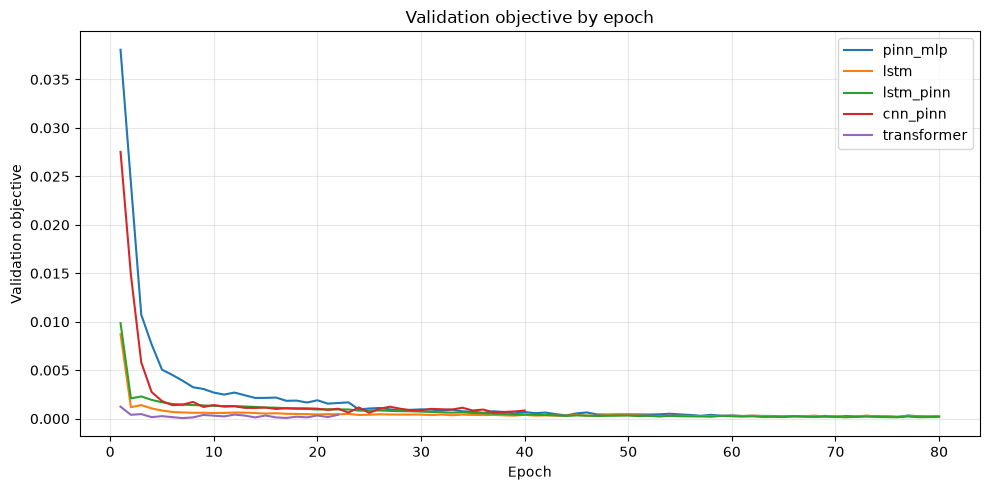

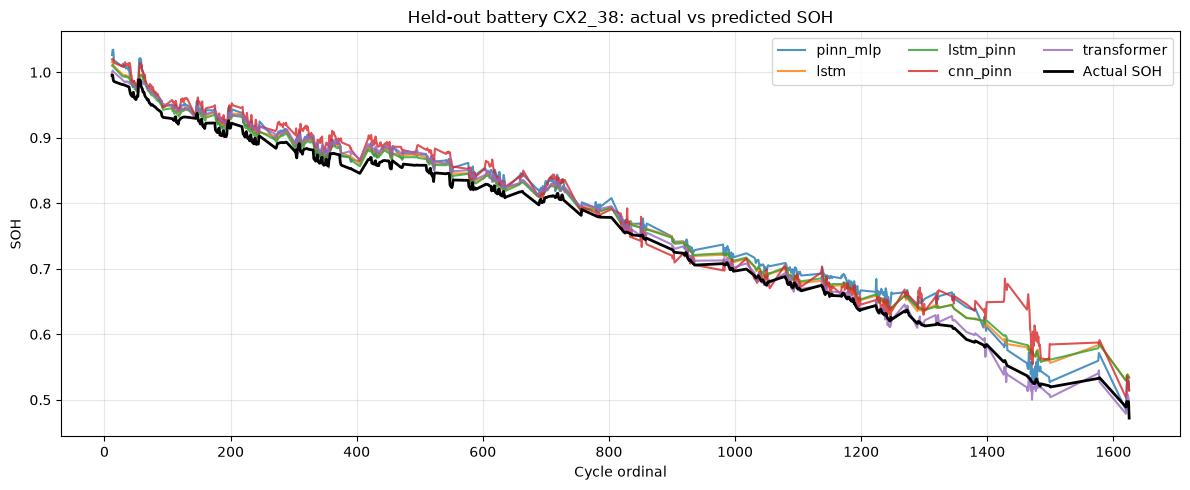

In [8]:
# Plot loss trajectories and one seed's test predictions; save visualizations.
fig,ax=plt.subplots(figsize=(10,5))
for name in MODEL_SPECS:
    hist=pd.read_csv(OUTPUT_DIR/f"{name}_seed{SEEDS[0]}_history.csv")
    ax.plot(hist.epoch,hist.validation_loss,label=name)
ax.set(title="Validation objective by epoch",xlabel="Epoch",ylabel="Validation objective")
ax.legend();ax.grid(alpha=.3);fig.tight_layout()
fig.savefig(OUTPUT_DIR/"validation_curves.png",dpi=180)
plt.show()

fig,ax=plt.subplots(figsize=(12,5))
for name in MODEL_SPECS:
    d=pd.read_csv(OUTPUT_DIR/f"{name}_seed{SEEDS[0]}_test_predictions.csv")
    cell=d.battery.iloc[0]; part=d[d.battery==cell].sort_values("cycle_ordinal")
    ax.plot(part.cycle_ordinal,part.predicted_soh,label=name,alpha=.8)
ax.plot(part.cycle_ordinal,part.soh,label="Actual SOH",color="black",linewidth=2)
ax.set(title=f"Held-out battery {cell}: actual vs predicted SOH",xlabel="Cycle ordinal",ylabel="SOH")
ax.legend(ncol=3);ax.grid(alpha=.3);fig.tight_layout()
fig.savefig(OUTPUT_DIR/"test_predictions.png",dpi=180)
plt.show()

## Research interpretation and safeguards

1. The PINN, LSTM–PINN, and CNN–PINN models use a **monotonic prediction penalty**, not a calibrated electrochemical degradation PDE. Report this accurately.
2. The supervised label is **measured SOH**. The monotonic constraint may harm performance when capacity fluctuates; inspect its effect against unregularized LSTM and Transformer.
3. Avoid optimizing architectures or the filtering threshold using the test results. Select settings using the CX2_36 validation battery; evaluate CX2_38 once for your final protocol.
4. Filtering may disproportionately remove difficult aging regions. Record sample counts and keep `train.csv` for an unfiltered sensitivity comparison.
5. With `SEQ_LEN=12`, single-cycle MLP is evaluated on the same **window endpoints** as all temporal models. Samples lacking twelve consecutive retained cycles are excluded from all models equally. CNN and Transformer use causal operations.
6. `MAPE_pct` is in percent; RMSE and MAE are fractions of nominal capacity. Multiply them by 100 for SOH percentage-point reporting.
7. A physically credible PINN extension requires measured current, temperature, elapsed time, and validated equation/parameters. Do not present the monotonic penalty as a full battery physics constraint.